# CS 577 Phase 3 Individual
**Group 17:** Anthony Alarcon (Member A)  
**Partner:** Maeki Kashana (Member B)  
**File:** `Group17_Anthony_Phase3_Individual.ipynb`

Figures in this notebook are labeled A1 to A4. The misleading plot is MA.


# Team Split

Agreed before plotting so the group notebook does not double up.

| Slot | Member A (Anthony) | Member B (Maeki) |
|---|---|---|
| 1, one qualitative | `YEAR` pulled from `PERIOD BEGIN` | `REGION NAME` |
| 2, one quantitative | `HOMES SOLD` | `MEDIAN_DOM` |
| 3, quant across qual | `MEDIAN_SALE_PRICE` by `YEAR` | `MEDIAN_SALE_PRICE` by `REGION NAME` |
| 4, two quantitative | `MEDIAN_SALE_PRICE` vs `MEDIAN_DOM` | `HOMES SOLD` vs `NEW LISTINGS` |

Sale price shows up in both notebooks, but not in the same slot with the same partner column.

Misleading principle: I break **scale**. Maeki picks context or perception so we do not match.

I am Member A. My figures are A1-A4 and MA. I am not including the Part 2C writeup in anything I send him yet. The handout says that stays hidden until the group detection check.


# Part 0: Starting Point

1. Research question, as it stands from Phase 1 / Phase 2:

How has the housing market changed over the period of a decade across the fifty U.S. states and have these housing markets in these states remained relatively similar throughout this time frame, or have they experienced either a substantial growth or decline in their markets?

2. Loaded `phase2_working.csv`. Shape is printed in the next cell. Phase 2 locked this file at 6528 rows by 10 columns after dropping Guam, Puerto Rico, and the U.S. Virgin Islands. No dataset switch.

3. Target I am treating as the thing to predict: `MEDIAN_SALE_PRICE` (monthly state median sale price, USD). The question is about whether markets grew or fell, and price is the cleanest single number for that. Part 3 checks this again.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_rows', 20)

df = pd.read_csv('phase2_working.csv', parse_dates=['PERIOD BEGIN', 'PERIOD END'])
df['YEAR'] = df['PERIOD BEGIN'].dt.year

print('shape', df.shape)
print('date range', df['PERIOD BEGIN'].min().date(), 'to', df['PERIOD BEGIN'].max().date())
print('regions', df['REGION NAME'].nunique())
print(df.dtypes)


shape (6528, 11)
date range 2016-01-01 to 2026-08-01
regions 51
PERIOD BEGIN         datetime64[ns]
PERIOD END           datetime64[ns]
REGION NAME                  object
HOMES SOLD                  float64
MEDIAN_SALE_PRICE           float64
MEDIAN_DOM                  float64
NEW LISTINGS                float64
ACTIVE LISTINGS             float64
PENDING SALES               float64
MEDIAN_LIST_PPSF            float64
YEAR                          int32
dtype: object


# Part 1: The Plot Menu

One chart per slot, using my half of the split.


## A1. Year counts

**Question.** Did every year in the cleaned file get the same number of state-months, or is the end of the window thinner than the start? That matters for the research question because a short 2026 would make a decade comparison unfair if I treated 2026 like a full year.

**Variables.** `YEAR` (qualitative, ordinal). Built from `PERIOD BEGIN` so the bar is a category count, not a time series.

**Why this chart.** Slot 1 wants a bar of counts. A line would pretend year is a continuous axis and hide that 2026 is just fewer rows. Counts are the point here.


YEAR
2016    612
2017    612
2018    612
2019    612
2020    612
2021    612
2022    612
2023    612
2024    612
2025    612
2026    408
Name: count, dtype: int64


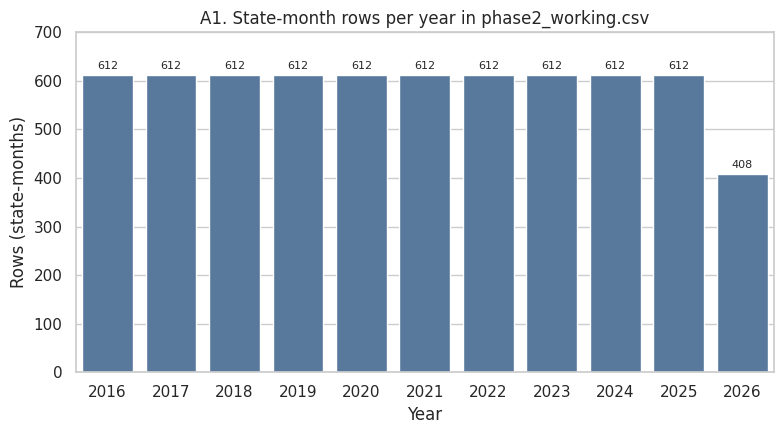

In [2]:
# A1
year_counts = df['YEAR'].value_counts().sort_index()
print(year_counts)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=year_counts.index.astype(str), y=year_counts.values, color='#4C78A8', ax=ax)
ax.set_title('A1. State-month rows per year in phase2_working.csv')
ax.set_xlabel('Year')
ax.set_ylabel('Rows (state-months)')
ax.set_ylim(0, 700)
for i, v in enumerate(year_counts.values):
    ax.text(i, v + 12, str(v), ha='center', fontsize=8)
fig.tight_layout()
plt.show()


**What it shows.** 2016 through 2025 each have 612 rows. That is 51 regions times 12 months. 2026 has 408 rows, which is 51 times 8 months (January through August). Nothing is missing inside a finished year. The file is balanced until the last partial year.

**What it does not show.** It does not say anything about prices or sales. A year with 612 rows can still be a weird market.

**Principle check.** Context. I labeled the y-axis as rows, not "activity," and I started the y-axis at 0 so 2026 does not look like the market collapsed. The short bar is a cutoff in the download, not a crash.


## A2. Homes sold

**Question.** Are monthly home sales spread pretty evenly across states, or do a few big states own the right tail? The research question asks if markets look similar. Volume is one way they do not.

**Variables.** `HOMES SOLD` (quantitative, discrete). Counts of homes sold in that state-month.

**Why this chart.** Slot 2. A histogram shows the shape better than a rug plot, which would just be a smear at this row count. I expected a long right tail, so a KDE alone would hide how piled up the small states are.


count     6528.0
mean      6856.5
std       7304.2
min        480.0
25%       1761.2
50%       4617.0
75%       9508.5
max      48549.0
Name: HOMES SOLD, dtype: float64
share under 5,000: 0.517
share under 10,000: 0.767


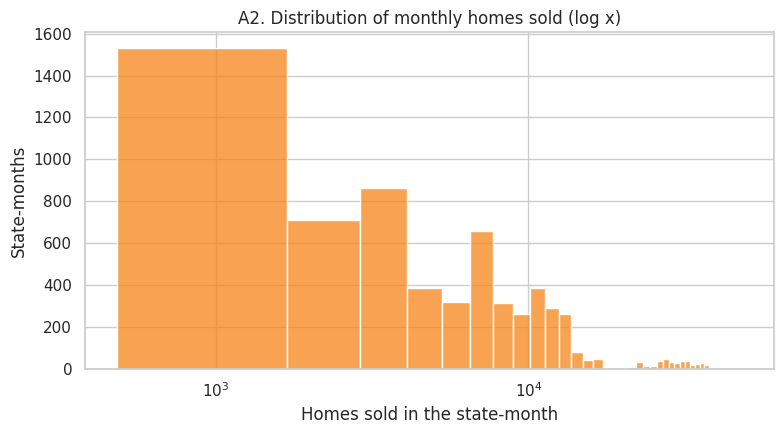

In [3]:
# A2
print(df['HOMES SOLD'].describe().round(1))
print('share under 5,000:', round((df['HOMES SOLD'] < 5000).mean(), 3))
print('share under 10,000:', round((df['HOMES SOLD'] < 10000).mean(), 3))

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(df['HOMES SOLD'], bins=40, color='#F58518', ax=ax)
ax.set_title('A2. Distribution of monthly homes sold (log x)')
ax.set_xlabel('Homes sold in the state-month')
ax.set_ylabel('State-months')
ax.set_xscale('log')
fig.tight_layout()
plt.show()


**What it shows.** The distribution is right skewed (skew about 2.3). Median is 4,617 homes, mean is about 6,856, max is 48,549. A little over half the rows are under 5,000, and about 77% are under 10,000. The long tail is the big states (California, Texas, Florida), not a data error. Min is 480, so there are no zero-sale months left after the Phase 2 territory drop.

**What it does not show.** A log axis compresses the big states, so it is easy to forget Florida can sell around 30k homes in a month while Wyoming sits under 1,000.

**Principle check.** Scale. On a linear x-axis most of the mass sat in the first couple bars. I switched the x-axis to log so the small-state pile and the big-state tail are both readable.


## A3. Sale price across years

**Question.** Did the typical state median sale price climb across the decade, or did states stay in the same band? This is the growth-or-not half of the research question.

**Variables.** `MEDIAN_SALE_PRICE` (quantitative, continuous, USD) across `YEAR` (qualitative, ordinal).

**Why this chart.** Slot 3. A box plot shows the middle and the spread for each year. Overlaid KDEs for 11 years would be a mess. A violin would show the same shift with more ink than I need.


        median      mean
YEAR                    
2016  200000.0  221699.0
2017  214200.0  233597.0
2018  224975.0  246650.0
2019  235000.0  259120.0
2020  258500.0  283236.0
2021  299950.0  325371.0
2022  334375.0  358065.0
2023  348250.0  365774.0
2024  360000.0  386287.0
2025  370000.0  397853.0
2026  375000.0  406179.0


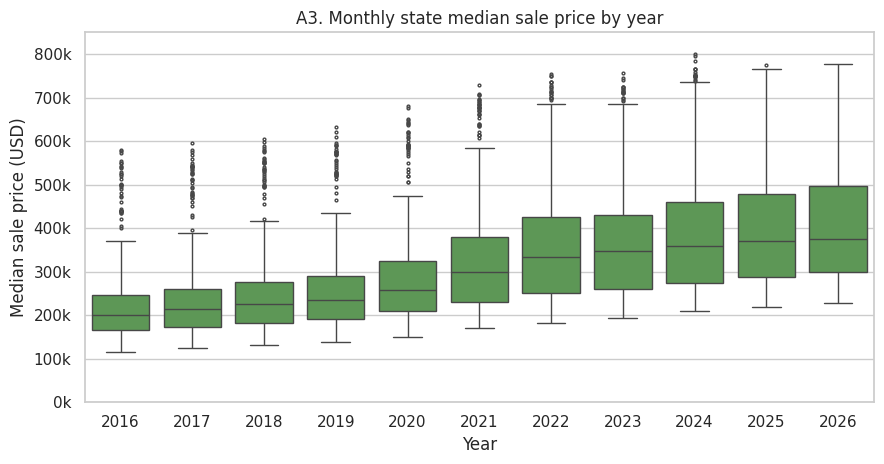

In [4]:
# A3
year_price = df.groupby('YEAR')['MEDIAN_SALE_PRICE'].agg(['median', 'mean']).round(0)
print(year_price)

fig, ax = plt.subplots(figsize=(9, 4.8))
sns.boxplot(
    data=df, x='YEAR', y='MEDIAN_SALE_PRICE',
    color='#54A24B', ax=ax, fliersize=2
)
ax.set_title('A3. Monthly state median sale price by year')
ax.set_xlabel('Year')
ax.set_ylabel('Median sale price (USD)')
ax.set_ylim(0, 850000)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k'))
fig.tight_layout()
plt.show()


**What it shows.** The box shifts up every year. Median of the state medians goes from about $200,000 in 2016 to about $334,000 in 2022 and about $375,000 in 2026 (2026 is only Jan-Aug). The jump is steeper from 2020 to 2022 than from 2016 to 2019. The boxes also sit higher without getting wildly wider, so states moved up together more than they split apart. Hawaii, D.C., and California stay in the top whisker the whole time. Highest single state-month in the file is $800,000.

**What it does not show.** A box plot hides which state is which. It also averages over seasons inside the year, so a spring bump and a winter dip get stacked in the same box.

**Principle check.** Scale. I kept the y-axis starting at 0. Starting near $200k would make the 2016-2019 climb look like a collapse-and-recovery. Context also: 2026 is an 8-month year, so that last box is not a full year.


## A4. Price vs days on market

**Question.** Do more expensive state-months also sit longer, or is price mostly separate from how fast homes move? If price and speed move together, growth in the research question is not just a dollar number.

**Variables.** `MEDIAN_SALE_PRICE` (quantitative, continuous, USD) and `MEDIAN_DOM` (quantitative, discrete, days).

**Why this chart.** Slot 4. A scatter is the direct comparison. Hex would hide the thin high-price band. I used alpha because 6,528 points pile up in the middle.


corr price vs days on market: -0.352


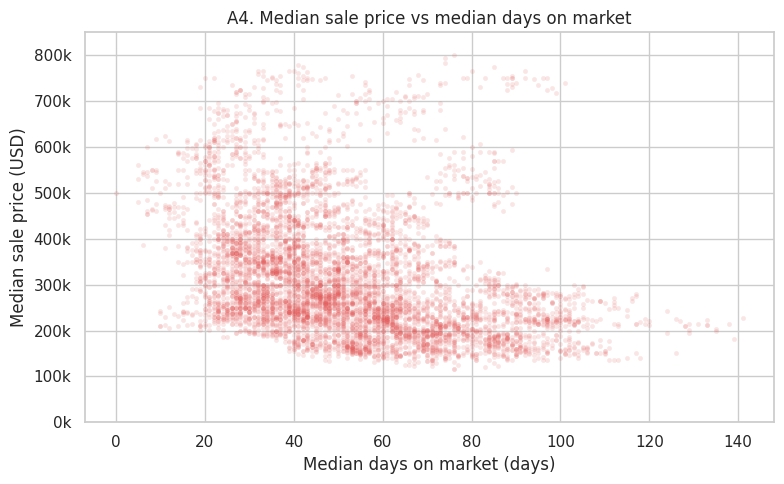

In [5]:
# A4
print('corr price vs days on market:', round(df['MEDIAN_SALE_PRICE'].corr(df['MEDIAN_DOM']), 3))

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(
    df['MEDIAN_DOM'], df['MEDIAN_SALE_PRICE'],
    alpha=0.15, s=12, c='#E45756', linewidths=0
)
ax.set_title('A4. Median sale price vs median days on market')
ax.set_xlabel('Median days on market (days)')
ax.set_ylabel('Median sale price (USD)')
ax.set_ylim(0, 850000)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k'))
fig.tight_layout()
plt.show()


**What it shows.** Correlation is about -0.35. Higher price state-months tend to have fewer days on market, but the cloud is wide. Plenty of $200k months sit at 30 days and plenty sit at 80. The expensive band (Hawaii, D.C., California, mostly above $500k) is not the slow band. Days on market in this file run from 0 to 141, with a mean around 52. Price runs from $115,000 to $800,000.

**What it does not show.** One point is a whole state-month, so a -0.35 correlation is not "a house sells faster because it is expensive." Population and year are both sitting under this cloud.

**Principle check.** Perception. Points pile up between about 30 and 70 days, so I set alpha to 0.15. A solid scatter would look like one blob and invent a tighter relationship than there is.


# Part 2: Lie on Purpose, Then Tell the Truth

**MISLEADING ON PURPOSE**

False headline: Typical state home prices more than doubled after 2016, and the later years are in a different league from the start of the file.

Principle I agreed to break: scale. Same rows and same column as the honest plot (`YEAR`, `MEDIAN_SALE_PRICE`). I did not edit any values.


YEAR
2016    221699.0
2017    233597.0
2018    246650.0
2019    259120.0
2020    283236.0
2021    325371.0
2022    358065.0
2023    365774.0
2024    386287.0
2025    397853.0
2026    406179.0
Name: MEDIAN_SALE_PRICE, dtype: float64
2016 mean 221699
2026 mean 406179
ratio 2026/2016 1.832


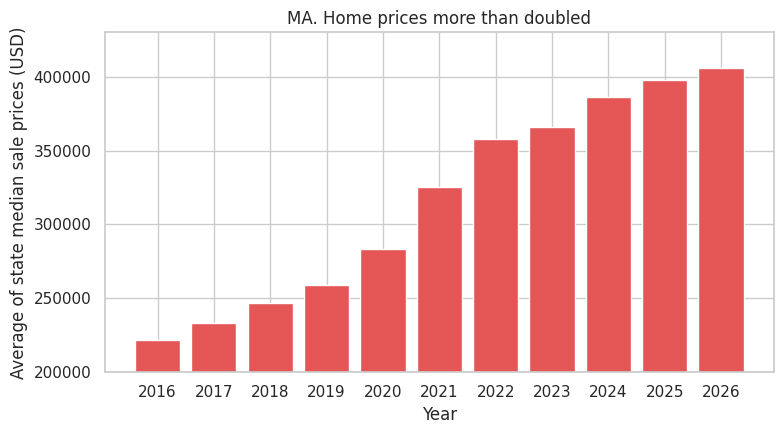

In [6]:
# MA misleading: yearly mean of state median sale price, y-axis chopped
yearly = df.groupby('YEAR')['MEDIAN_SALE_PRICE'].mean()
print(yearly.round(0))
print('2016 mean', round(yearly.loc[2016]))
print('2026 mean', round(yearly.loc[2026]))
print('ratio 2026/2016', round(yearly.loc[2026] / yearly.loc[2016], 3))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(yearly.index.astype(str), yearly.values, color='#E45756')
ax.set_ylim(200000, 430000)  # scale trick: chop off the baseline
ax.set_title('MA. Home prices more than doubled')
ax.set_xlabel('Year')
ax.set_ylabel('Average of state median sale prices (USD)')
fig.tight_layout()
plt.show()


## 2B. Honest plot

Same yearly means, same years, y-axis starts at 0, title does not claim a doubling.


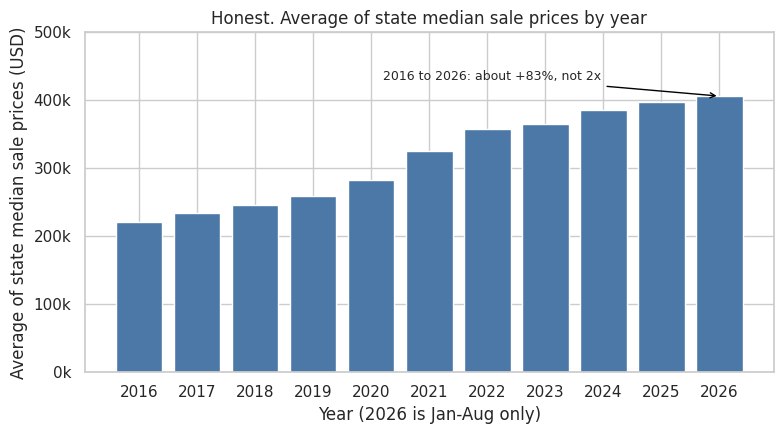

In [7]:
# honest version of MA
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(yearly.index.astype(str), yearly.values, color='#4C78A8')
ax.set_ylim(0, 500000)
ax.set_title('Honest. Average of state median sale prices by year')
ax.set_xlabel('Year (2026 is Jan-Aug only)')
ax.set_ylabel('Average of state median sale prices (USD)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k'))
ax.annotate(
    '2016 to 2026: about +83%, not 2x',
    xy=(10, yearly.loc[2026]),
    xytext=(4.2, 430000),
    fontsize=9,
    arrowprops=dict(arrowstyle='->', color='black')
)
fig.tight_layout()
plt.show()


## 2C. How the trick works

I broke scale. The damage is `ax.set_ylim(200000, 430000)` on the misleading bar chart, plus a title that says prices more than doubled. The bars are yearly means of `MEDIAN_SALE_PRICE`, about $222k in 2016 and about $406k in 2026. That is roughly 1.83 times, not more than double. Chopping the axis makes the 2016 bar look like a stub and the 2026 bar look like it fills the chart, so a reader treats the climb as a different order of magnitude. The honest plot uses the same means and starts at 0. The climb is real, especially 2020 to 2022, but the false headline does not survive. 2026 is also only eight months, which the misleading title does not say.


# Part 3: Target Signal Check

1. **Target and type.** `MEDIAN_SALE_PRICE`, quantitative continuous (USD). Arithmetic means something here, so this is regression, not classification. Default start is linear regression.

2. **Evidence plot.** Price against days on market, with a fitted line added on top of the A4 scatter. Days on market is the feature I expected to matter most for "is this market hot." It is only a moderate link.


slope USD per extra day: -2084.2
intercept: 422131.9
baseline (mean price): 313916.1


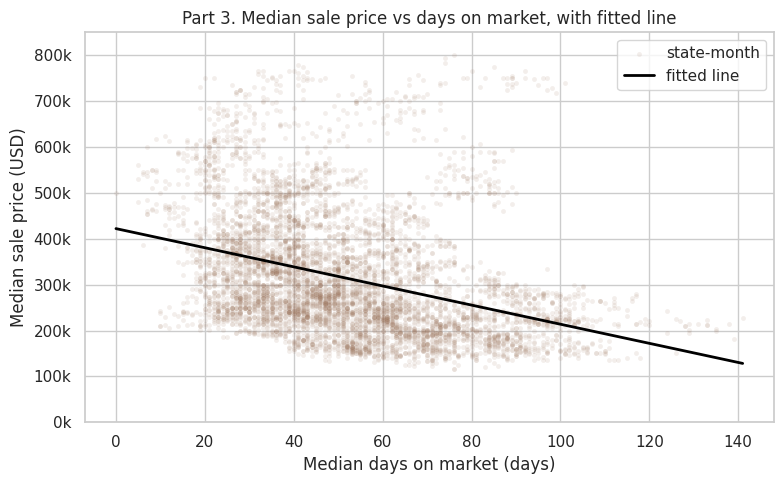

In [8]:
# Part 3 evidence: A4 scatter plus a fitted line
x = df['MEDIAN_DOM'].to_numpy()
y = df['MEDIAN_SALE_PRICE'].to_numpy()
slope, intercept = np.polyfit(x, y, 1)
print('slope USD per extra day:', round(slope, 1))
print('intercept:', round(intercept, 1))
print('baseline (mean price):', round(y.mean(), 1))

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, alpha=0.12, s=12, c='#9D755D', linewidths=0, label='state-month')
xs = np.linspace(x.min(), x.max(), 100)
ax.plot(xs, slope * xs + intercept, color='black', linewidth=2, label='fitted line')
ax.set_title('Part 3. Median sale price vs days on market, with fitted line')
ax.set_xlabel('Median days on market (days)')
ax.set_ylabel('Median sale price (USD)')
ax.set_ylim(0, 850000)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k'))
ax.legend()
fig.tight_layout()
plt.show()


3. **Lean.** I would start with linear regression, not a forest. The fitted line slopes down (about $1,600 off the state median per extra day on market), which is a one-sentence effect, and that is what a linear model is for. The cloud is too wide to call it a tight band, and days on market fell into 2021-2022 and then rose again while price kept climbing, so year is doing something a single line misses. If Phase 4 is about prediction more than a sentence, a forest on price with year and state would probably beat the line. For explaining the research question, linear with year in it is the better first model.

4. **Leakage check.** Nothing in the working file is built from `MEDIAN_SALE_PRICE`. I checked `HOMES SOLD`, `NEW LISTINGS`, `ACTIVE LISTINGS`, `PENDING SALES`, `MEDIAN_DOM`, and `MEDIAN_LIST_PPSF`. List price per sq ft is related, but it is a listing stat, not the sale price rewritten. Year-over-year price columns were already dropped in Phase 2, which is good, because those would have leaked the recent level of the target. No column is filled in after the sale in a way that copies the target.

Baseline for Phase 4: predict the mean, about $313,900, for every row. Anything we fit has to beat that.


# AI use

Grok was used for plotting syntax (seaborn hist, box, and the polyfit line) and to keep the section order matched to the handout. I did not paste the housing CSV into the tool. The false headline, the 2C note, and the Part 3 lean are written for this notebook.
